# 09 - Model Evaluation


/Users/dhruvvatsa/hadoop-docker/python/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
KNN,0.873,0.641,0.421,0.509,0.772
SVM,0.865,0.549,0.767,0.640,0.901
Logistic Regression,0.851,0.516,0.785,0.623,0.911
Decision Tree,0.848,0.509,0.861,0.640,0.921


<Figure size 1000x500 with 0 Axes>

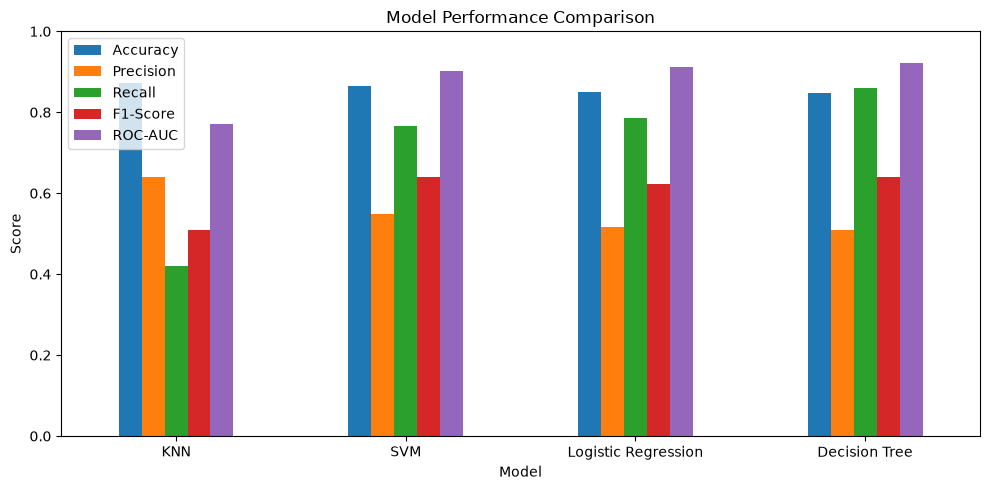

Best model by F1-Score: SVM

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.88      0.92      2059
           1       0.55      0.77      0.64       382

    accuracy                           0.86      2441
   macro avg       0.75      0.82      0.78      2441
weighted avg       0.89      0.86      0.87      2441



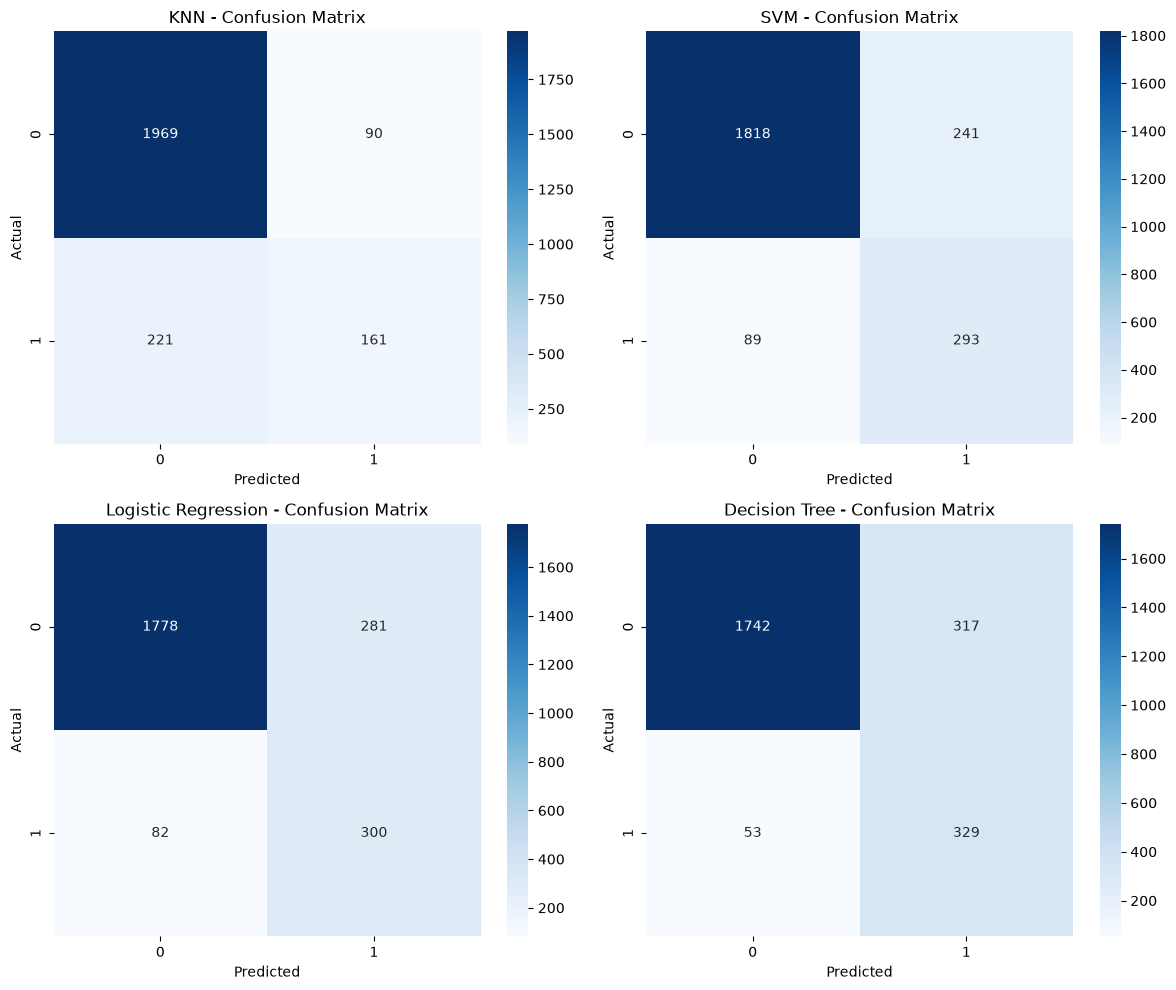

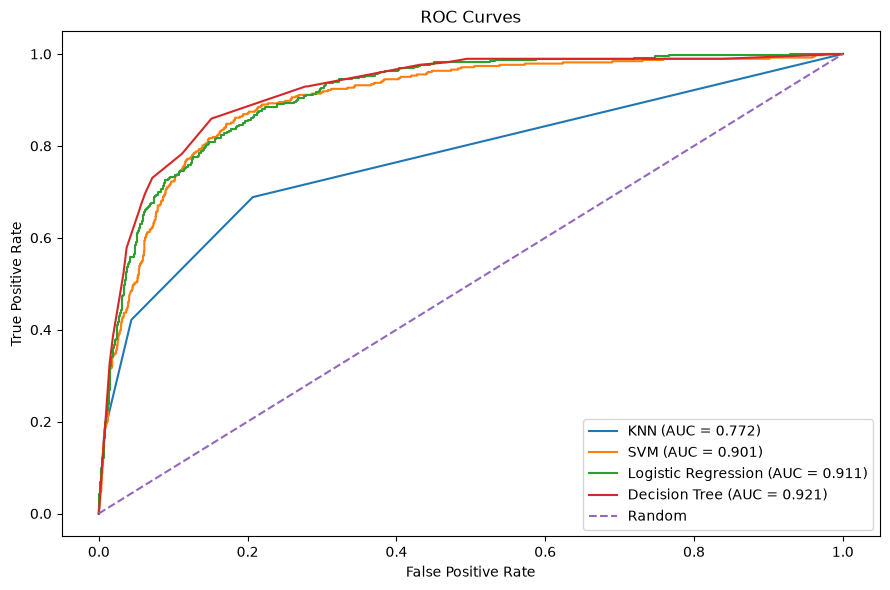

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('online_shoppers_intention.csv')
df = df.drop_duplicates().copy()
df['Weekend'] = df['Weekend'].astype(int)
df['Revenue'] = df['Revenue'].astype(int)

df['Total_Pages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['Total_Duration'] = (
    df['Administrative_Duration'] +
    df['Informational_Duration'] +
    df['ProductRelated_Duration']
)

df = pd.get_dummies(
    df,
    columns=['Month', 'VisitorType'],
    drop_first=True,
    dtype=int
)

X = df.drop('Revenue', axis=1)
y = df['Revenue']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import numpy as np

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

k_values = list(range(1, 22, 2))
knn_scores = [
    cross_val_score(
        KNeighborsClassifier(n_neighbors=k),
        X_train_s, y_train, cv=5, scoring='f1'
    ).mean()
    for k in k_values
]
best_k = k_values[np.argmax(knn_scores)]

depth_values = [3, 5, 10, 15, 20, None]
dt_scores = [
    cross_val_score(
        DecisionTreeClassifier(max_depth=d, random_state=42),
        X_train, y_train, cv=5, scoring='f1'
    ).mean()
    for d in depth_values
]
best_depth = depth_values[np.argmax(dt_scores)]


from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

models = {
    'KNN': (KNeighborsClassifier(n_neighbors=best_k), X_train_s, X_test_s),
    'SVM': (SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42), X_train_s, X_test_s),
    'Logistic Regression': (LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42), X_train_s, X_test_s),
    'Decision Tree': (DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=42), X_train, X_test)
}

rows = []
predictions = {}
probabilities = {}

for name, (model, train_x, test_x) in models.items():
    model.fit(train_x, y_train)
    y_pred = model.predict(test_x)
    y_prob = model.predict_proba(test_x)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results = pd.DataFrame(rows).set_index('Model').round(3)
display(results)

plt.figure(figsize=(10, 5))
results[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].plot(
    kind='bar', figsize=(10, 5)
)
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

best_model_name = results['F1-Score'].idxmax()
print('Best model by F1-Score:', best_model_name)
print('\nClassification Report:')
print(classification_report(
    y_test,
    predictions[best_model_name],
    zero_division=0
))

# Confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    sns.heatmap(
        confusion_matrix(y_test, y_pred),
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )
    ax.set_title(f'{name} - Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

# ROC curves
plt.figure(figsize=(9, 6))

for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(
        fpr, tpr,
        label=f'{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})'
    )

plt.plot([0, 1], [0, 1], '--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.tight_layout()
plt.show()
